# Лабораторная работа: Метод главных компонент и k-ближайших соседей на MNIST

## О задании

В этой работе вы:
1. Реализуете **метод главных компонент (PCA)** — один из базовых методов понижения размерности
2. Реализуете **метод k-ближайших соседей (kNN)** — простейший метрический классификатор
3. Примените оба метода для распознавания рукописных цифр из базы **MNIST**
4. Исследуете, как понижение размерности влияет на качество классификации

---

## Часть 0. Подготовка данных (обязательно, но без баллов)

### Теория: Что такое MNIST?

**MNIST** (Modified National Institute of Standards and Technology) — это классический датасет для задач распознавания рукописных цифр. Он состоит из:
- **70 000 изображений** рукописных цифр от 0 до 9
- Каждое изображение имеет размер **28×28 пикселей** (784 признака)
- **60 000** изображений для обучения, **10 000** для тестирования

Каждое изображение — это матрица 28×28, где каждый пиксель — число от 0 (чёрный) до 255 (белый).

### Задание 0.1: Загрузка данных

```python
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
```

**Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.

```python
# TODO: Нарисуйте 10 примеров (по одному на каждую цифру)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
# Ваш код здесь
```

### Задание 0.3: Подготовка данных

Для дальнейшей работы:
1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)

```python
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
```

---

## Часть 1. Метод главных компонент (PCA)

### Теория: Зачем нужен PCA?

**Проблема:** У нас 784 признака (пикселя) на каждое изображение. Многие из них **коррелированы** (соседние пиксели часто имеют похожие значения), а некоторые **неинформативны** (например, углы картинки почти всегда чёрные).

**Идея PCA:** Найти такие **новые оси** (главные компоненты), вдоль которых данные **сильнее всего разбросаны**. Тогда:
- Несколько первых компонент опишут **большую часть** информации
- Остальные компоненты можно **отбросить** без существенной потери качества

### Математика PCA

Пусть у нас есть матрица данных $X \in \mathbb{R}^{n \times d}$ (n объектов, d признаков).

**Шаг 1. Центрирование.** Вычитаем среднее по каждому признаку:
$$ X_{centered} = X - \bar{X} $$
где $\bar{X}$ — вектор средних значений по каждому столбцу.

**Шаг 2. Матрица ковариации:**
$$ C = \frac{1}{n-1} X_{centered}^T X_{centered} \in \mathbb{R}^{d \times d} $$

**Шаг 3. Собственные векторы и значения.** Находим:
$$ C v_i = \lambda_i v_i $$
где $\lambda_1 \ge \lambda_2 \ge ... \ge \lambda_d$ — собственные значения, $v_i$ — собственные векторы.

**Шаг 4. Преобразование.** Новые координаты объекта:
$$ Y = X_{centered} \cdot V_k $$
где $V_k$ — матрица из первых $k$ собственных векторов.

### Важная связь: собственные числа и дисперсия

**Собственное число $\lambda_i$ равно дисперсии данных вдоль $i$-й главной компоненты.**

Доля объяснённой дисперсии для $k$ первых компонент:
$$ \text{Explained Variance Ratio} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i} $$

---

### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.

```python
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # TODO: Реализуйте обучение
        
        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Шаг 2-3: Используйте np.linalg.svd (рекомендуется!) или np.linalg.eig
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # TODO: Сохраните собственные значения и векторы
        # explained_variance = S^2 / (n - 1)
        # components = Vt
        
        # TODO: Отсортируйте (SVD уже возвращает в порядке убывания)
        # TODO: Если n_components задано, оставьте только первые n_components
        
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        # TODO: Реализуйте преобразование
        pass
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)
```

**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:

```python
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
```

**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии

```python
# TODO: Обучите PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# TODO: Постройте графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
# axes[0].plot(...)
# axes[0].set_xlabel('Номер компоненты')
# axes[0].set_ylabel('Собственное значение (дисперсия)')
# axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
# cumulative = np.cumsum(pca_full.explained_variance_)
# cumulative /= cumulative[-1]
# axes[1].plot(...)
# axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
# axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
# axes[1].set_xlabel('Число компонент')
# axes[1].set_ylabel('Доля объяснённой дисперсии')
# axes[1].set_title('Кумулятивная дисперсия')
# axes[1].legend()

plt.tight_layout()
plt.show()
```

**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.

```python
# TODO: Преобразуйте данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# TODO: Постройте scatter plot
plt.figure(figsize=(10, 8))
# for digit in range(10):
#     mask = (y == digit)
#     plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
# plt.legend()
# plt.xlabel('Первая главная компонента')
# plt.ylabel('Вторая главная компонента')
# plt.title('Данные MNIST в первых двух главных компонентах')
# plt.show()
```

**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

---

## Часть 2. Метод k-ближайших соседей (kNN)

### Теория: Как работает kNN?

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$

### Задание 2.1: Реализация my_kNN

```python
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        # TODO: Сохраните X и y
        pass
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        # TODO: Реализуйте предсказание
        # Подсказка: используйте np.argsort для поиска k ближайших
        # Для подсчёта самого частого класса используйте np.bincount или scipy.stats.mode
        pass
```

**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
```

**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:

```python
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
```

**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.

```python
# TODO: Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    # TODO: Обучите kNN, посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(8, 5))
# plt.plot(k_values, accuracies, 'o-')
# plt.xlabel('Число соседей k')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа соседей')
# plt.grid(True)
# plt.show()
```

**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

---

## Часть 3. PCA + kNN: Понижение размерности для классификации

### Теория: Зачем комбинировать PCA и kNN?

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?

### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.

```python
# TODO: Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # TODO: 
    # 1. Примените PCA к X_train и X_test
    # 2. Обучите kNN на преобразованных данных
    # 3. Посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, accuracies_pca, 'o-')
# plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
# plt.xlabel('Число главных компонент')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа компонент PCA')
# plt.legend()
# plt.grid(True)
# plt.show()
```

**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.

```python
import time

# TODO: Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    # ... обучение и предсказание ...
    elapsed = time.time() - start
    times.append(elapsed)

# TODO: Постройте график времени
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, times, 'o-')
# plt.xlabel('Число компонент')
# plt.ylabel('Время (сек)')
# plt.title('Время работы kNN в зависимости от числа компонент')
# plt.grid(True)
# plt.show()
```

**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.

```python
# TODO: Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    # ...
    for j, k in enumerate(k_grid):
        # Обучите kNN
        # ...
        pass

# TODO: Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
# sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
#             xticklabels=k_grid, yticklabels=n_components_grid,
#             cmap='viridis')
# plt.xlabel('Число соседей k')
# plt.ylabel('Число компонент PCA')
# plt.title('Точность классификации MNIST')
# plt.show()
```

**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?

---

## Часть 4. Выводы (в конце ноутбука, обязательно)

Напишите текстовый вывод (5-10 предложений) по всей работе. Ответьте на вопросы:

1. **Что такое PCA?** Как он работает? Зачем нужен?
2. **Что такое kNN?** Как работает? Какие у него есть плюсы и минусы?
3. **Как PCA влияет на качество kNN?** Что лучше — использовать все признаки или уменьшить размерность?
4. **Какова оптимальная размерность для MNIST?** Почему?
5. **Что было самым сложным** при выполнении работы?
6. **Что было самым интересным?**

---

## Подсказки и советы

### Совет 1: Используйте SVD вместо eig
В `my_PCA.fit()` используйте `np.linalg.svd`, а не `np.linalg.eig`. SVD работает быстрее и численно устойчивее.

### Совет 2: Проверяйте размерности
После каждого преобразования выводите `shape` массивов. Это поможет избежать ошибок.

### Совет 3: kNN может работать медленно
Если предсказание занимает больше минуты, попробуйте:
- Уменьшить выборку (взять первые 5000 объектов)
- Использовать матричные вычисления расстояний

### Совет 4: Не бойтесь экспериментировать
Если что-то не работает как ожидается — меняйте параметры, рисуйте графики, смотрите на данные.

### Совет 5: Интерпретируйте результаты
Не просто стройте графики, а **объясняйте**, что вы видите. Например: "Точность падает при k > 15, потому что..."

**Удачи!**


---
# Решение

## Часть 0. Подготовка данных

### Задание 0.1: Загрузка данных

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
print(f"Тип данных: {X_train_full.dtype}, диапазон: [{X_train_full.min()}, {X_train_full.max()}]")
print(f"Размерность одного изображения: {X_train_full.shape[1:]} -> {np.prod(X_train_full.shape[1:])} признаков")

Extracting MNIST-data\train-images-idx3-ubyte.gz


Extracting MNIST-data\train-labels-idx1-ubyte.gz
Extracting MNIST-data\t10k-images-idx3-ubyte.gz
Extracting MNIST-data\t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)
Тип данных: uint8, диапазон: [0, 255]
Размерность одного изображения: (28, 28, 1) -> 784 признаков


**Ответ.** Одно изображение имеет форму 28×28×1 (одноканальное, оттенки серого), т.е. у каждого объекта **28·28 = 784 признака** — яркости пикселей от 0 до 255.

### Задание 0.2: Визуализация примеров

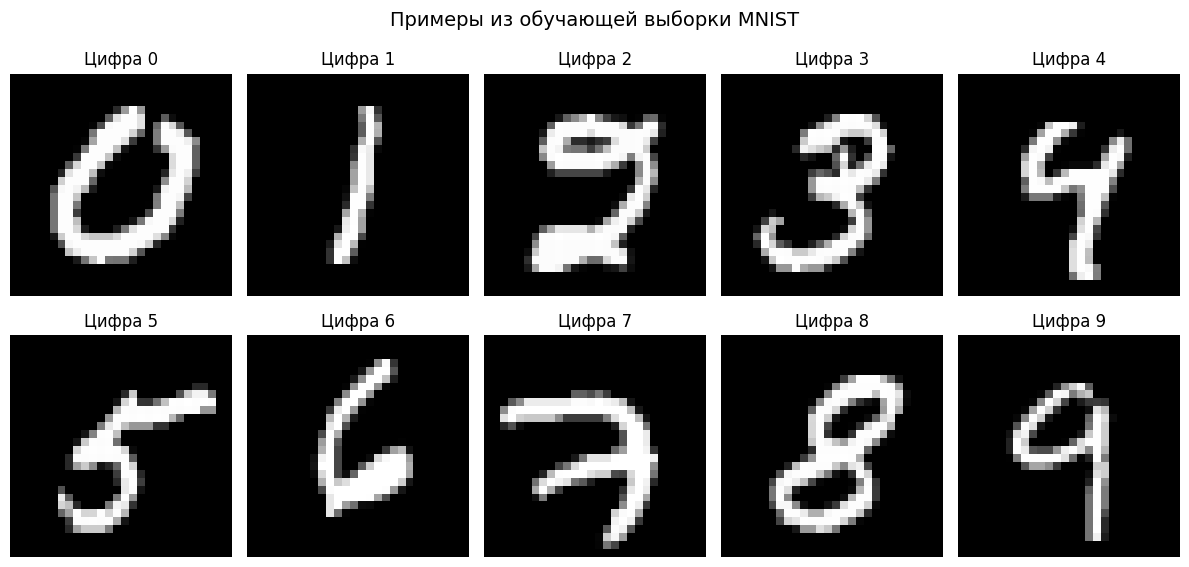

Число примеров каждого класса в обучающей выборке: [5444 6179 5470 5638 5307 4987 5417 5715 5389 5454]


In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == digit)[0][0]          # первый пример каждой цифры
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'Цифра {digit}')
    ax.axis('off')
plt.suptitle('Примеры из обучающей выборки MNIST', fontsize=14)
plt.tight_layout()
plt.show()

print('Число примеров каждого класса в обучающей выборке:', np.bincount(y_train_full))

### Задание 0.3: Подготовка данных

In [3]:
# Официальную тестовую выборку MNIST сохраним отдельно (используем её в конце для финальной проверки),
# т.к. ниже имя X_test будет переопределено разбиением train_test_split
X_mnist_test = X_test.reshape(X_test.shape[0], -1).astype(np.float32) / 255.0
y_mnist_test = y_test

# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
print(f"Диапазон X: [{X.min()}, {X.max()}]")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


Диапазон X: [0.0, 1.0]


## Часть 1. Метод главных компонент (PCA)

### Задание 1.1: Реализация my_PCA

Реализация через SVD центрированной матрицы: если $X_c = U S V^T$, то $C = \frac{1}{n-1}X_c^TX_c = V\frac{S^2}{n-1}V^T$, т.е. строки $V^T$ — собственные векторы ковариационной матрицы, а $\lambda_i = \frac{s_i^2}{n-1}$. Знаки компонент фиксируются так же, как в sklearn (наибольшая по модулю координата каждой компоненты положительна), поэтому результаты можно сравнивать напрямую.

In [4]:
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None                # главные компоненты (собственные векторы), shape (k, d)
        self.explained_variance_ = None        # собственные значения, shape (k,)
        self.explained_variance_ratio_ = None  # доли объяснённой дисперсии, shape (k,)
        self.singular_values_ = None
        self.mean_ = None                      # среднее по каждому признаку

    def fit(self, X):
        """
        Обучает PCA на данных X.

        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        n_samples, n_features = X.shape

        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Шаг 2-3: SVD центрированной матрицы: X_c = U @ diag(S) @ Vt
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

        # Фиксируем знаки (как sklearn): наибольшая по модулю координата каждой компоненты > 0
        signs = np.sign(Vt[np.arange(Vt.shape[0]), np.argmax(np.abs(Vt), axis=1)])
        Vt *= signs[:, None]

        # Шаг 4: SVD уже возвращает сингулярные числа по убыванию -> сортировка не нужна
        explained_variance = S ** 2 / (n_samples - 1)    # собственные значения ковариации
        total_variance = explained_variance.sum()

        # Шаг 5: оставляем первые n_components компонент
        k = min(n_samples, n_features) if self.n_components is None else self.n_components
        self.components_ = Vt[:k]
        self.explained_variance_ = explained_variance[:k]
        self.explained_variance_ratio_ = explained_variance[:k] / total_variance
        self.singular_values_ = S[:k]
        return self

    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент:
        Y = (X - mean) @ components.T

        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        return (X - self.mean_) @ self.components_.T

    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)

### Задание 1.2: Проверка реализации

In [5]:
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

print(f"\nМакс. отн. расхождение собственных значений: "
      f"{np.max(np.abs(my_pca.explained_variance_ - sk_pca.explained_variance_) / sk_pca.explained_variance_):.2e}")
print(f"Макс. расхождение долей дисперсии: "
      f"{np.max(np.abs(my_pca.explained_variance_ratio_ - sk_pca.explained_variance_ratio_)):.2e}")
print(f"Макс. расхождение |Y| (с точностью до знака): {np.max(np.abs(np.abs(Y_my) - np.abs(Y_sk))):.2e}")
print(f"Совпадение с учётом знака (allclose): {np.allclose(Y_my, Y_sk, atol=1e-3)}")
print(f"Решатель, который выбрал sklearn: {sk_pca._fit_svd_solver}")

# sklearn по умолчанию выбрал приближённый randomized SVD -> сравним ещё и с точным решателем
sk_pca_full = PCA(n_components=50, svd_solver='full')
Y_sk_full = sk_pca_full.fit_transform(X[:1000])
print(f"\nС точным решателем svd_solver='full':")
print(f"  макс. отн. расхождение собственных значений: "
      f"{np.max(np.abs(my_pca.explained_variance_ - sk_pca_full.explained_variance_) / sk_pca_full.explained_variance_):.2e}")
print(f"  макс. расхождение Y (с учётом знака): {np.max(np.abs(Y_my - Y_sk_full)):.2e}")
print(f"  allclose: {np.allclose(Y_my, Y_sk_full, atol=1e-3)}")

# Где именно расходится randomized-вариант: по номерам компонент
diff_by_comp = np.max(np.abs(np.abs(Y_my) - np.abs(Y_sk)), axis=0)
print(f"\nРасхождение с randomized по компонентам: первые 10 — {diff_by_comp[:10].max():.1e}, "
      f"компоненты 41–50 — {diff_by_comp[40:].max():.1e}")

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)

Макс. отн. расхождение собственных значений: 4.18e-03
Макс. расхождение долей дисперсии: 1.26e-05
Макс. расхождение |Y| (с точностью до знака): 8.00e-01
Совпадение с учётом знака (allclose): False
Решатель, который выбрал sklearn: randomized



С точным решателем svd_solver='full':
  макс. отн. расхождение собственных значений: 1.45e-06
  макс. расхождение Y (с учётом знака): 2.77e-04
  allclose: True

Расхождение с randomized по компонентам: первые 10 — 8.7e-05, компоненты 41–50 — 8.0e-01


**Ответ.** **Да, собственные значения совпадают.** Суммы равны (45.48), доли объяснённой дисперсии расходятся лишь в 5–6 знаке, формы результатов одинаковые (1000, 50).

Однако при параметрах по умолчанию sklearn выбрал **приближённый решатель `randomized`** (данные больше 500×500, а нужно мало компонент). Поэтому проекции на первые ~10 компонент совпадают (расхождение ~1e-4), а на последние компоненты (41–50) заметно отличаются. Это особенность randomized SVD, а не ошибка: у последних компонент близкие собственные значения, и приближённый метод определяет их направления менее точно. Числа меняются от запуска к запуску, так как random_state не задан.

С **точным решателем `svd_solver='full'`** совпадение полное: собственные значения расходятся на ~1e-6 (относительно), а проекции $Y$ совпадают **вместе со знаком** с точностью ~3e-4, т.е. до ошибок округления float32. Знаки совпадают потому, что в `my_PCA` используется то же соглашение, что в sklearn. **Реализация верна.**

### Задание 1.3: Визуализация дисперсии

PCA на 60000 объектах: 10.38 с, компонент: 784


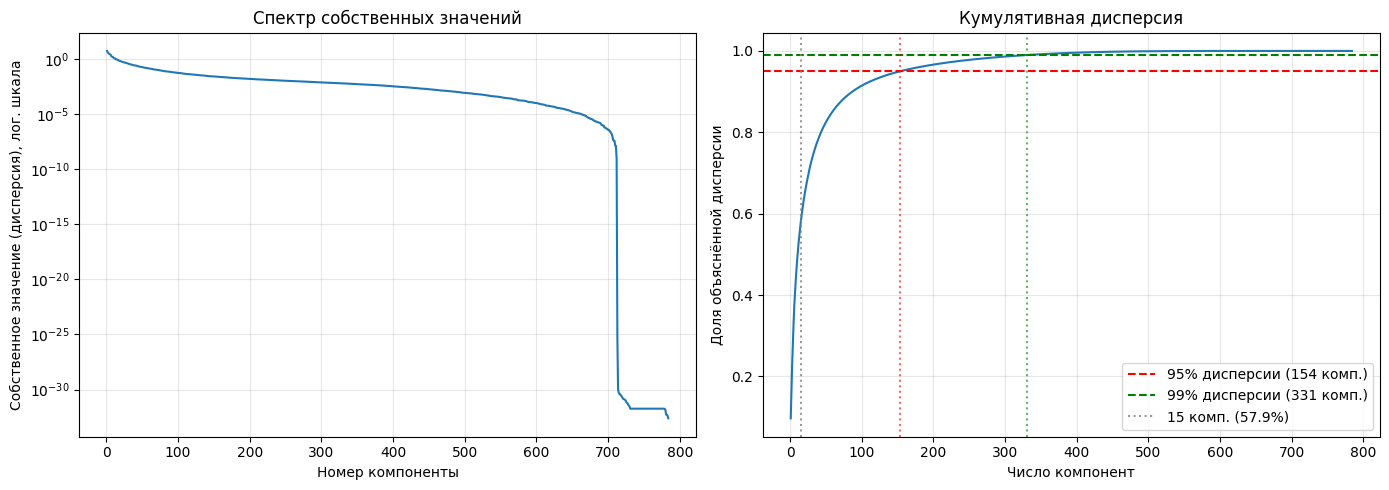

Первые 15 компонент объясняют 57.93% дисперсии
Для 95% дисперсии нужно 154 компонент, для 99% — 331
Первая компонента: 9.70%, первые 2: 16.80%, первые 50: 82.46%
Компонент с практически нулевой дисперсией (< 1e-10): 72


In [6]:
pca_full = my_PCA()
t0 = time.time()
pca_full.fit(X)
print(f'PCA на {X.shape[0]} объектах: {time.time() - t0:.2f} с, компонент: {pca_full.components_.shape[0]}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(np.arange(1, len(pca_full.explained_variance_) + 1), pca_full.explained_variance_)
axes[0].set_yscale('log')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия), лог. шкала')
axes[0].set_title('Спектр собственных значений')
axes[0].grid(True, alpha=0.3)

# График 2: кумулятивная дисперсия
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
n99 = int(np.searchsorted(cumulative, 0.99) + 1)
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axhline(y=0.95, color='r', linestyle='--', label=f'95% дисперсии ({n95} комп.)')
axes[1].axhline(y=0.99, color='g', linestyle='--', label=f'99% дисперсии ({n99} комп.)')
axes[1].axvline(x=n95, color='r', linestyle=':', alpha=0.6)
axes[1].axvline(x=n99, color='g', linestyle=':', alpha=0.6)
axes[1].axvline(x=15, color='gray', linestyle=':', alpha=0.8, label=f'15 комп. ({cumulative[14]:.1%})')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Первые 15 компонент объясняют {cumulative[14]:.2%} дисперсии')
print(f'Для 95% дисперсии нужно {n95} компонент, для 99% — {n99}')
print(f'Первая компонента: {cumulative[0]:.2%}, первые 2: {cumulative[1]:.2%}, первые 50: {cumulative[49]:.2%}')
print(f'Компонент с практически нулевой дисперсией (< 1e-10): {(pca_full.explained_variance_ < 1e-10).sum()}')

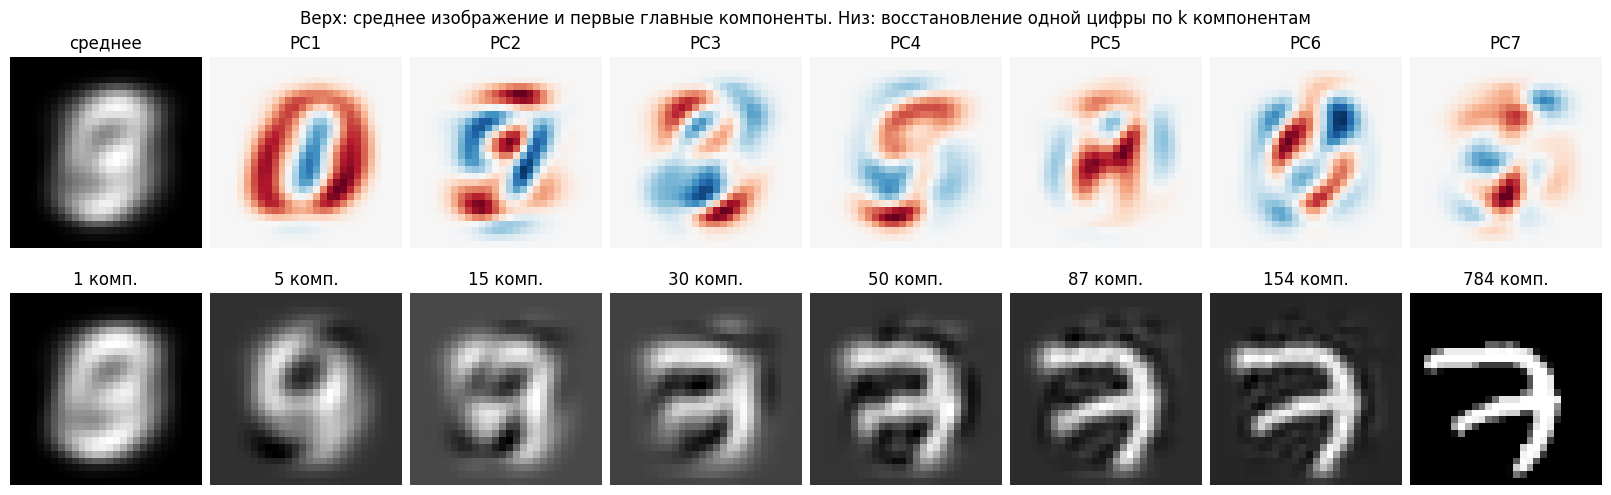

In [7]:
# Дополнительно: как выглядят главные компоненты и восстановление по ним
fig, axes = plt.subplots(2, 8, figsize=(16, 5), layout='constrained')
axes[0, 0].imshow(pca_full.mean_.reshape(28, 28), cmap='gray'); axes[0, 0].set_title('среднее')
for i in range(7):
    v = pca_full.components_[i].reshape(28, 28)
    lim = np.abs(v).max()
    axes[0, i + 1].imshow(v, cmap='RdBu_r', vmin=-lim, vmax=lim); axes[0, i + 1].set_title(f'PC{i + 1}')
x0 = X[0]
for ax, k in zip(axes[1], [1, 5, 15, 30, 50, 87, 154, 784]):
    z = (x0 - pca_full.mean_) @ pca_full.components_[:k].T
    ax.imshow((pca_full.mean_ + z @ pca_full.components_[:k]).reshape(28, 28), cmap='gray')
    ax.set_title(f'{k} комп.')
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('Верх: среднее изображение и первые главные компоненты. Низ: восстановление одной цифры по k компонентам')
plt.show()

**Ответы на вопросы 1.3.**

1. **Первые 15 главных компонент покрывают ≈ 57.9% дисперсии.** Первая компонента объясняет ≈ 9.7%, первые две — ≈ 16.8%, первые 50 — ≈ 82.5%.
2. **Для 95% дисперсии нужно 154 компоненты** (для 99% — 331). Это всего ~20% от исходных 784 признаков. При этом 72 компоненты имеют практически нулевую дисперсию: это пиксели по краям, которые почти у всех изображений чёрные.
3. **Связь собственных чисел и дисперсии.** Собственный вектор $v_i$ ковариационной матрицы задаёт направление в пространстве признаков, а собственное число $\lambda_i = v_i^T C v_i$ — это дисперсия проекций данных на это направление. Первая компонента — направление, вдоль которого данные «разбросаны» сильнее всего, вторая — направление наибольшего разброса среди ортогональных первой, и т.д. Сумма всех $\lambda_i$ равна следу $C$, т.е. суммарной дисперсии всех пикселей. Поэтому отношение $\sum_{i\le k}\lambda_i / \sum_i \lambda_i$ показывает, какую долю общей изменчивости сохраняют первые k компонент, а отброшенные компоненты с маленькими $\lambda_i$ почти не несут информации.

По картинкам компонент видно, что PC1 похожа на «ноль минус единица»: она отличает широкие округлые цифры от узких вертикальных. Следующие компоненты описывают наклон и отдельные штрихи. Восстановление цифры по 30–50 компонентам уже уверенно читается, а по 154 почти не отличается от оригинала (остаётся лёгкий шум фона).

### Задание 1.4: Визуализация данных в первых двух компонентах

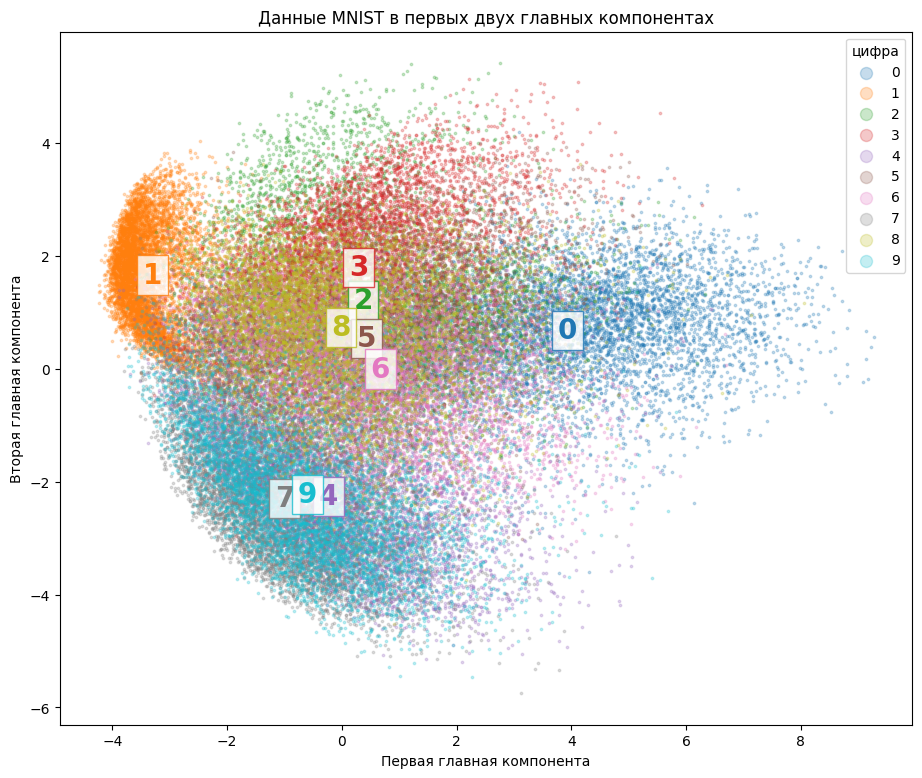

Первые 2 компоненты объясняют 16.80% дисперсии
0: центр = (  3.93,   0.69)
1: центр = ( -3.30,   1.67)
2: центр = (  0.37,   1.21)
3: центр = (  0.29,   1.80)
4: центр = ( -0.23,  -2.26)
5: центр = (  0.42,   0.54)
6: центр = (  0.67,   0.00)
7: центр = ( -1.00,  -2.29)
8: центр = ( -0.01,   0.74)
9: центр = ( -0.60,  -2.23)


In [8]:
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(11, 9))
colors = plt.cm.tab10(np.arange(10))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.25, s=3, color=colors[digit])
# центры классов — чтобы было видно, где находится каждая цифра
for digit in range(10):
    cx, cy = Y_2d[y == digit].mean(axis=0)
    plt.text(cx, cy, str(digit), fontsize=20, weight='bold', ha='center', va='center',
             color=colors[digit], bbox=dict(facecolor='white', alpha=0.8, edgecolor=colors[digit]))
plt.legend(markerscale=5, title='цифра')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

print(f'Первые 2 компоненты объясняют {pca_2d.explained_variance_ratio_.sum():.2%} дисперсии')
centers = np.array([Y_2d[y == d].mean(axis=0) for d in range(10)])
for d in range(10):
    print(f'{d}: центр = ({centers[d, 0]:6.2f}, {centers[d, 1]:6.2f})')

**Ответ.** Классы видны **лишь частично**. Две компоненты объясняют всего ≈ 16.8% дисперсии, поэтому большая часть облака перемешана.
- **«0» и «1» хорошо отделены**: они находятся на противоположных концах первой компоненты (0 справа, 1 слева). PC1 по сути измеряет «сколько чернил на периметре против центра»: у нуля широкий круглый контур, у единицы — одна тонкая вертикальная линия.
- **«4», «7» и «9» сливаются в одну группу внизу** (отрицательная PC2). У всех трёх есть похожая наклонная/вертикальная черта справа и открытая или маленькая верхняя часть, а нижняя половина почти пустая.
- **«2», «3», «5», «6», «8» перемешаны в центре**: это цифры со «средним» количеством штрихов и похожим распределением яркости, и на одной плоскости их не различить.

PCA ищет направления максимальной дисперсии и не использует метки классов, поэтому первые две компоненты не обязаны разделять классы. Для разделения нужно больше компонент (что и видно в части 3) или методы, которые учитывают метки (например, LDA).

## Часть 2. Метод k-ближайших соседей (kNN)

### Задание 2.1: Реализация my_kNN

Реализация полностью векторная: квадраты расстояний считаются через $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2\langle x, x'\rangle$ (одно матричное умножение на блок), тестовые объекты обрабатываются блоками по 1000, чтобы матрица расстояний помещалась в память (18000×42000 float32 заняла бы ~3 ГБ). Вместо полной сортировки `np.argsort` используется `np.argpartition` (выбор k наименьших за O(n)). Голосование — через подсчёт голосов по классам, при равенстве голосов выбирается меньшая метка (как в `scipy.stats.mode` / sklearn).

Метод `kneighbors` (как в sklearn) возвращает индексы соседей, отсортированные по расстоянию. Он позволяет в экспериментах с разными k один раз найти соседей и затем голосовать по первым k из них.

In [9]:
class my_kNN:
    def __init__(self, n_neighbors=5, batch_size=1000):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        batch_size : int
            Сколько тестовых объектов обрабатывать за раз (ограничивает память)
        """
        self.n_neighbors = n_neighbors
        self.batch_size = batch_size
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        """
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        self._train_sq = np.sum(self.X_train ** 2, axis=1)       # ||x'||^2 — считаем один раз
        return self

    def kneighbors(self, X, n_neighbors=None):
        """
        Индексы n_neighbors ближайших объектов обучающей выборки для каждого объекта X,
        отсортированные по возрастанию расстояния. shape (n_samples, n_neighbors)
        """
        k = self.n_neighbors if n_neighbors is None else n_neighbors
        X = np.asarray(X, dtype=np.float32)
        result = np.empty((X.shape[0], k), dtype=np.int64)
        for start in range(0, X.shape[0], self.batch_size):
            batch = X[start:start + self.batch_size]
            # ||x - x'||^2 = ||x||^2 + ||x'||^2 - 2 <x, x'>
            d2 = (np.sum(batch ** 2, axis=1)[:, None] + self._train_sq[None, :]
                  - 2.0 * batch @ self.X_train.T)
            idx = np.argpartition(d2, k - 1, axis=1)[:, :k]             # k ближайших (без порядка)
            order = np.argsort(np.take_along_axis(d2, idx, axis=1), axis=1)
            result[start:start + len(batch)] = np.take_along_axis(idx, order, axis=1)
        return result

    def _vote(self, neighbor_idx):
        """Самый частый класс среди соседей (при равенстве — меньшая метка)."""
        labels = self.y_train[neighbor_idx]                              # (n, k)
        votes = (labels[:, :, None] == self.classes_[None, None, :]).sum(axis=1)   # (n, n_classes)
        return self.classes_[np.argmax(votes, axis=1)]

    def predict(self, X):
        """
        Предсказывает классы для объектов X.

        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        return self._vote(self.kneighbors(X))

In [10]:
# Маленький sanity-check на игрушечных данных
toy_X = np.array([[0, 0], [0, 1], [1, 0], [10, 10], [10, 11], [11, 10]], dtype=float)
toy_y = np.array([0, 0, 0, 1, 1, 1])
toy = my_kNN(n_neighbors=3).fit(toy_X, toy_y)
print(toy.predict(np.array([[0.5, 0.5], [10.5, 10.5], [3, 3], [8, 8]])))   # ожидаем [0 1 0 1]

[0 1 0 1]


### Задание 2.2: Проверка реализации

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(f'Обучение: {X_train.shape}, тест: {X_test.shape}')

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
t0 = time.time()
y_pred_my = my_knn.predict(X_test)
time_my = time.time() - t0

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}  (время предсказания: {time_my:.1f} с)")

Обучение: (42000, 784), тест: (18000, 784)


Точность my_kNN: 0.9668  (время предсказания: 14.7 с)


**Ответ.** Точность my_kNN при k = 5 равна **0.9668 (96.7%)**, что намного выше 10% случайного угадывания, — реализация работает правильно. Предсказание для 18 000 объектов по 42 000 обучающим занимает ~15 с за счёт матричного вычисления расстояний и обработки блоками.

### Задание 2.3: Сравнение с sklearn

In [12]:
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
t0 = time.time()
y_pred_sk = sk_knn.predict(X_test)
time_sk = time.time() - t0

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}  (время предсказания: {time_sk:.1f} с)")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
print(f"Предсказания различаются на {np.sum(y_pred_my != y_pred_sk)} объектах из {len(y_test)}")

Точность sklearn kNN: 0.9668  (время предсказания: 16.1 с)
Разница: 0.0000
Предсказания различаются на 0 объектах из 18000


**Ответ.** Результаты **полностью совпадают**: точность sklearn тоже 0.9668, а предсказания различаются на **0 объектах из 18 000**. Значит, реализация эквивалентна `KNeighborsClassifier` (евклидова метрика, голосование большинством). При этом собственная реализация работает не медленнее sklearn (~15 с против ~16 с), так как использует одно матричное умножение на блок.

### Задание 2.4: Эксперимент с числом соседей

Обучение kNN — это просто запоминание выборки, поэтому соседей ищем один раз (сразу 30 штук, отсортированных по расстоянию), а для каждого k голосуем по первым k из них. Результат совпадает с отдельным запуском `my_kNN(n_neighbors=k)`, но поиск расстояний выполняется один раз вместо восьми.

Поиск 30 соседей: 17.0 с
k =  1: точность = 0.9680
k =  3: точность = 0.9690
k =  5: точность = 0.9668
k =  7: точность = 0.9649
k = 10: точность = 0.9628
k = 15: точность = 0.9594
k = 20: точность = 0.9564
k = 30: точность = 0.9519


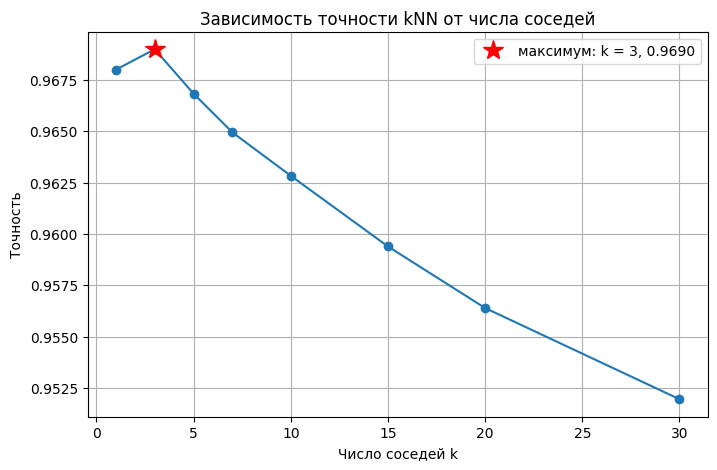

In [13]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

knn = my_kNN().fit(X_train, y_train)
t0 = time.time()
neighbors = knn.kneighbors(X_test, n_neighbors=max(k_values))
print(f'Поиск {max(k_values)} соседей: {time.time() - t0:.1f} с')

for k in k_values:
    y_pred = knn._vote(neighbors[:, :k])
    accuracies.append(accuracy_score(y_test, y_pred))
    print(f'k = {k:2d}: точность = {accuracies[-1]:.4f}')

# Контроль: для k=5 должно совпасть с отдельным запуском из 2.2
assert accuracies[k_values.index(5)] == accuracy_my

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
best_k = k_values[int(np.argmax(accuracies))]
plt.plot(best_k, max(accuracies), 'r*', markersize=15, label=f'максимум: k = {best_k}, {max(accuracies):.4f}')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.legend()
plt.grid(True)
plt.show()

**Ответ.** - **Максимальная точность при k = 3: 0.9690.** При k = 1 — 0.9680, затем точность монотонно падает: 0.9668 (k = 5), …, 0.9519 (k = 30).
- **При малых k** (особенно k = 1) предсказание зависит от единственного ближайшего соседа. Если это «выброс» — неаккуратно написанная цифра или цифра другого класса, похожая по написанию, — ответ будет неверным. Модель переобучается: высокая дисперсия, неустойчивость к шуму. Голосование трёх соседей сглаживает такие случайные ошибки.
- **При больших k** в число соседей попадают уже далёкие объекты, в том числе из соседних похожих классов (4/9, 3/5/8, 7/1). Граница между классами размывается, особенно для объектов вблизи неё, и классификатор становится «слишком гладким» (недообучение, высокое смещение). На MNIST классы плотные и данных много, поэтому оптимальное k небольшое.

## Часть 3. PCA + kNN: Понижение размерности для классификации

**Вопрос для размышления (гипотеза до эксперимента):** скорость должна заметно вырасти, так как стоимость вычисления расстояний пропорциональна размерности. Качество при умеренном числе компонент может даже немного улучшиться: последние компоненты в основном содержат шум и мелкие индивидуальные особенности почерка, которые мешают метрике. При слишком малом числе компонент качество, наоборот, упадёт.

### Задание 3.1: Применение PCA перед kNN

PCA обучается **только на X_train** (иначе информация из теста «протекает» в признаки), затем X_train и X_test переводятся в новые координаты. В том же цикле замеряем время (используется в 3.2), отдельно для PCA и для kNN.

n_comp =   1: точность = 0.2661 | PCA  6.89 с, kNN 12.28 с


n_comp =   2: точность = 0.4119 | PCA  7.29 с, kNN 11.58 с


n_comp =   5: точность = 0.7341 | PCA  7.10 с, kNN 11.08 с


n_comp =  10: точность = 0.9273 | PCA  7.00 с, kNN 11.33 с


n_comp =  15: точность = 0.9581 | PCA  6.72 с, kNN 11.24 с


n_comp =  20: точность = 0.9683 | PCA  7.40 с, kNN 11.31 с


... (4 outputs left out)

n_comp = 200: точность = 0.9683 | PCA  6.95 с, kNN 12.29 с


n_comp = 300: точность = 0.9679 | PCA  7.08 с, kNN 13.10 с


n_comp = 500: точность = 0.9669 | PCA  7.68 с, kNN 14.76 с


n_comp = 784: точность = 0.9668 | PCA  7.98 с, kNN 16.61 с


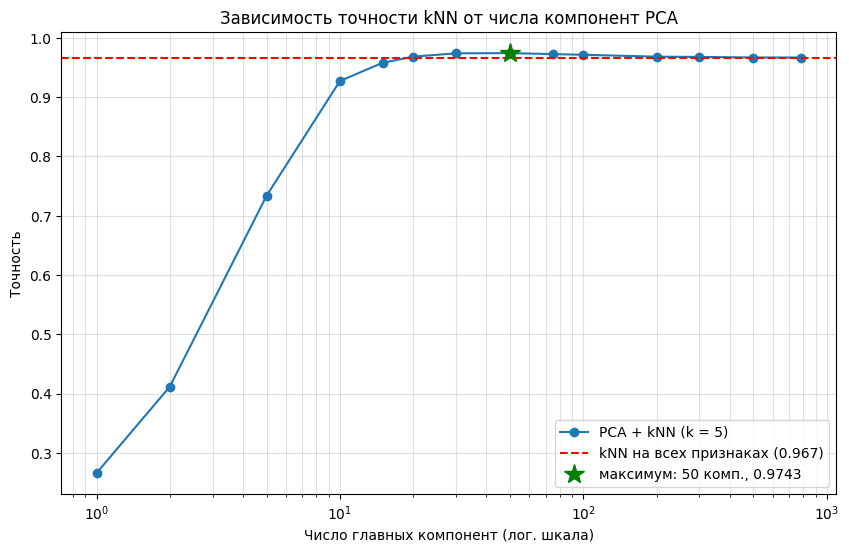

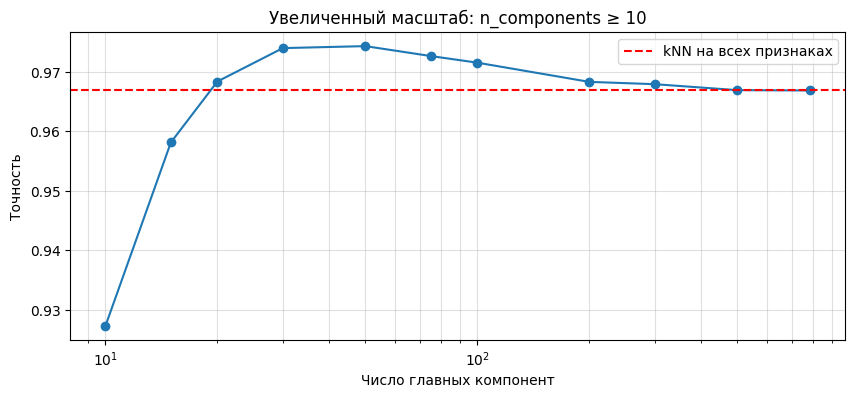

In [14]:
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []
times_pca, times_knn = [], []

for n_comp in n_components_list:
    # 1. Примените PCA к X_train и X_test
    t0 = time.time()
    pca = my_PCA(n_components=n_comp).fit(X_train)
    Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)
    t1 = time.time()
    # 2. Обучите kNN на преобразованных данных
    knn = my_kNN(n_neighbors=5).fit(Z_train, y_train)
    y_pred = knn.predict(Z_test)
    t2 = time.time()
    # 3. Посчитайте accuracy
    accuracies_pca.append(accuracy_score(y_test, y_pred))
    times_pca.append(t1 - t0); times_knn.append(t2 - t1)
    print(f'n_comp = {n_comp:3d}: точность = {accuracies_pca[-1]:.4f} | PCA {t1 - t0:5.2f} с, kNN {t2 - t1:5.2f} с')

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-', label='PCA + kNN (k = 5)')
plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
best_i = int(np.argmax(accuracies_pca))
plt.plot(n_components_list[best_i], accuracies_pca[best_i], 'g*', markersize=15,
         label=f'максимум: {n_components_list[best_i]} комп., {accuracies_pca[best_i]:.4f}')
plt.xscale('log')
plt.xlabel('Число главных компонент (лог. шкала)')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

# Тот же график в «рабочем» диапазоне
plt.figure(figsize=(10, 4))
mask = np.array(n_components_list) >= 10
plt.plot(np.array(n_components_list)[mask], np.array(accuracies_pca)[mask], 'o-')
plt.axhline(y=accuracy_my, color='r', linestyle='--', label='kNN на всех признаках')
plt.xscale('log'); plt.xlabel('Число главных компонент'); plt.ylabel('Точность')
plt.title('Увеличенный масштаб: n_components ≥ 10'); plt.legend(); plt.grid(True, which='both', alpha=0.4)
plt.show()

**Ответы на вопросы 3.1.**

1. **Максимальная точность — при 50 компонентах: 0.9743** (при 30 — почти столько же, 0.9739). Плато высокой точности ≈ 0.972–0.974 находится в диапазоне ~30–100 компонент.
2. **Да, удалось превзойти kNN на всех 784 признаках** (0.9668): с 20 до 500 компонент точность выше или равна, а лучший результат больше на ~0.75 п.п. Это ≈ 22% меньше ошибок (3.3% → 2.6%). При 784 компонентах точность ровно равна точности на сырых данных: это ожидаемо, так как полный PCA — это только сдвиг и поворот осей, а евклидовы расстояния при этом не меняются.
3. **При слишком малом числе компонент** (1–10) точность резко падает: 0.27 при 1 компоненте, 0.41 при 2, 0.73 при 5, 0.93 при 10. В 1–2 измерениях разные цифры проецируются в одну область (см. scatter plot в 1.4), и информации для различения 10 классов просто нет: 1 компонента сохраняет < 10% дисперсии. «Ближайшие» в такой проекции объекты часто оказываются другими цифрами.

Почему точность выше, чем на всех признаках: последние компоненты с малой дисперсией описывают в основном шум и индивидуальные мелкие особенности почерка (толщину линий, небольшие сдвиги, «рваные» края). В евклидовом расстоянии они суммируются по сотням координат и «размывают» действительно значимые различия. Отбросив их, PCA работает как **фильтр шума**, и расстояния лучше отражают форму цифры.

### Задание 3.2: Исследование времени работы

Время замерено в цикле задания 3.1: отдельно обучение PCA + преобразование выборок и обучение + предсказание kNN.

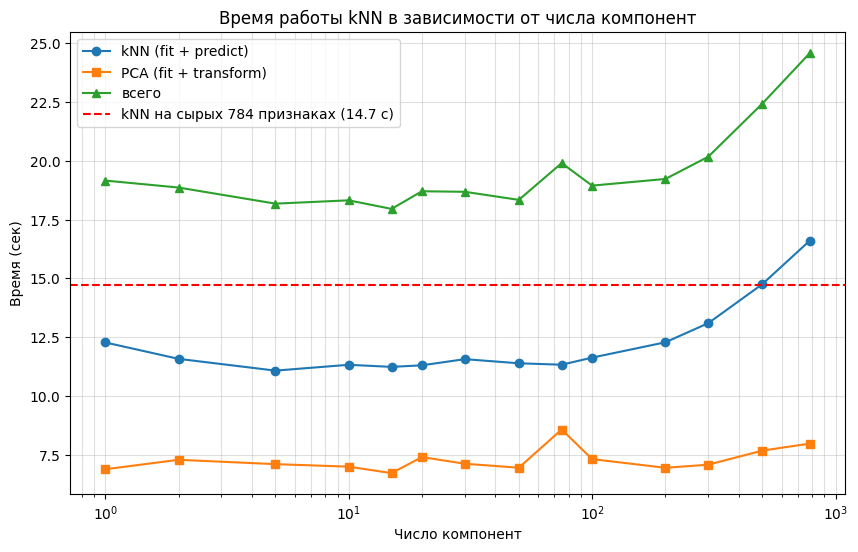

n_comp =   1: kNN 12.28 с (ускорение относительно сырых данных ×1.20), PCA 6.89 с
n_comp =   2: kNN 11.58 с (ускорение относительно сырых данных ×1.27), PCA 7.29 с
n_comp =   5: kNN 11.08 с (ускорение относительно сырых данных ×1.33), PCA 7.10 с
n_comp =  10: kNN 11.33 с (ускорение относительно сырых данных ×1.30), PCA 7.00 с
n_comp =  15: kNN 11.24 с (ускорение относительно сырых данных ×1.31), PCA 6.72 с
n_comp =  20: kNN 11.31 с (ускорение относительно сырых данных ×1.30), PCA 7.40 с
n_comp =  30: kNN 11.57 с (ускорение относительно сырых данных ×1.27), PCA 7.12 с
n_comp =  50: kNN 11.39 с (ускорение относительно сырых данных ×1.29), PCA 6.95 с
n_comp =  75: kNN 11.33 с (ускорение относительно сырых данных ×1.30), PCA 8.58 с
n_comp = 100: kNN 11.63 с (ускорение относительно сырых данных ×1.27), PCA 7.32 с
n_comp = 200: kNN 12.29 с (ускорение относительно сырых данных ×1.20), PCA 6.95 с
n_comp = 300: kNN 13.10 с (ускорение относительно сырых данных ×1.13), PCA 7.08 с
n_comp = 500: kN

In [15]:
times = [tp + tk for tp, tk in zip(times_pca, times_knn)]

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times_knn, 'o-', label='kNN (fit + predict)')
plt.plot(n_components_list, times_pca, 's-', label='PCA (fit + transform)')
plt.plot(n_components_list, times, '^-', label='всего')
plt.axhline(y=time_my, color='r', linestyle='--', label=f'kNN на сырых 784 признаках ({time_my:.1f} с)')
plt.xscale('log')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

for n, tp, tk in zip(n_components_list, times_pca, times_knn):
    print(f'n_comp = {n:3d}: kNN {tk:5.2f} с (ускорение относительно сырых данных ×{time_my / tk:.2f}), PCA {tp:4.2f} с')

Почему время kNN почти не зависит от числа компонент? Разложим предсказание на этапы для одного блока из 1000 тестовых объектов: (1) матричное умножение $\langle x, x'\rangle$, стоимость $O(n_{test} \cdot n_{train} \cdot d)$; (2) сборка матрицы квадратов расстояний и (3) `argpartition` по ней, стоимость $O(n_{test} \cdot n_{train})$, **не зависит от d**.

Время на весь тест (18 блоков по 1000), сек:
    d | умножение | матрица d² | argpartition
    1 |      3.49 |       3.61 |         6.23
   10 |      2.46 |       3.40 |         6.11
   50 |      3.24 |       3.39 |         6.13
  100 |      3.16 |       3.56 |         6.09
  300 |      5.09 |       3.36 |         6.05
  784 |      7.48 |       3.46 |         6.30


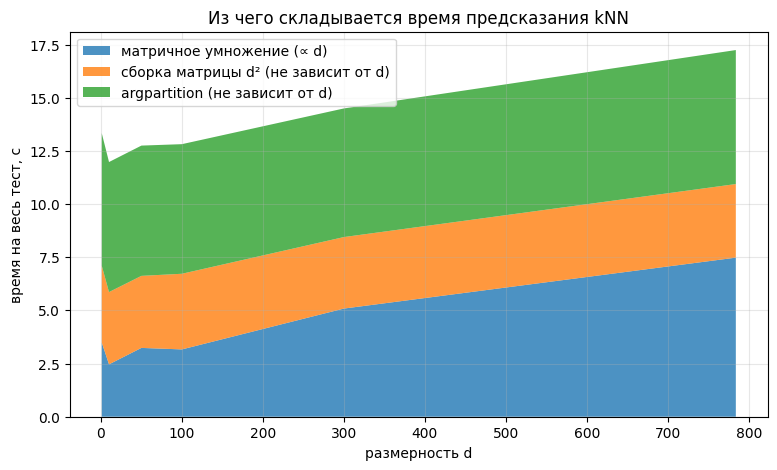

In [16]:
def profile_block(d, n_rep=3):
    Ztr = np.ascontiguousarray(Z_tr_full[:, :d]); Zte = np.ascontiguousarray(Z_te_full[:1000, :d])
    tr_sq = np.sum(Ztr ** 2, axis=1)
    t_mm = t_d2 = t_part = 0
    for _ in range(n_rep):
        t0 = time.perf_counter(); G = Zte @ Ztr.T
        t1 = time.perf_counter(); d2 = np.sum(Zte ** 2, axis=1)[:, None] + tr_sq[None, :] - 2.0 * G
        t2 = time.perf_counter(); np.argpartition(d2, 4, axis=1)
        t3 = time.perf_counter()
        t_mm += t1 - t0; t_d2 += t2 - t1; t_part += t3 - t2
    return t_mm / n_rep, t_d2 / n_rep, t_part / n_rep

pca_prof = my_PCA().fit(X_train)
Z_tr_full = pca_prof.transform(X_train).astype(np.float32)
Z_te_full = pca_prof.transform(X_test).astype(np.float32)

dims = [1, 10, 50, 100, 300, 784]
prof = np.array([profile_block(d) for d in dims])
n_blocks = int(np.ceil(len(X_test) / 1000))
print(f'Время на весь тест ({n_blocks} блоков по 1000), сек:')
print(f'{"d":>5} | {"умножение":>9} | {"матрица d²":>10} | {"argpartition":>12}')
for d, (a, b, c) in zip(dims, prof * n_blocks):
    print(f'{d:5d} | {a:9.2f} | {b:10.2f} | {c:12.2f}')

plt.figure(figsize=(9, 5))
plt.stackplot(dims, (prof * n_blocks).T, labels=['матричное умножение (∝ d)', 'сборка матрицы d² (не зависит от d)', 'argpartition (не зависит от d)'], alpha=0.8)
plt.xlabel('размерность d'); plt.ylabel('время на весь тест, с'); plt.title('Из чего складывается время предсказания kNN')
plt.legend(loc='upper left'); plt.grid(True, alpha=0.3)
plt.show()

**Ответ.** **Время kNN уменьшается, но слабее, чем можно было ожидать:** с ~16.6 с при 784 компонентах до ~11–12 с при ≤ 100 компонентах (≈ ×1.3–1.5). Ниже ~100 компонент время почти не меняется. (Абсолютные значения времени зависят от загрузки компьютера и немного меняются от запуска к запуску, но картина сохраняется.)

Профилирование показывает причину. Предсказание состоит из трёх этапов:
- **матричное умножение** (стоимость $\propto d$): ~7.5 с при d = 784 → ~2.5–3.5 с при d ≤ 100. Эта часть ускоряется в 2–3 раза;
- **сборка матрицы квадратов расстояний** 18 000×42 000 (~3.4 с) и **`argpartition`** по ней (~6.1 с) **не зависят от d**: их стоимость $O(n_{test}\cdot n_{train})$.

При d = 784 умножение составляет заметную часть времени, а при малых d доминирует постоянная часть ~9.5 с. Поэтому после ~100 компонент время выходит на плато. При очень малых d (d = 1) умножение даже не быстрее, чем при 50: BLAS неэффективен на «тонких» матрицах, там всё упирается в запись большой матрицы результата в память.

Время PCA (~7 с) тоже почти не зависит от n_components, так как `my_PCA` всегда вычисляет полное SVD матрицы 42 000×784 и только потом отбрасывает лишние компоненты.

**Вывод:** понижение размерности ускоряет именно вычисление расстояний (пропорционально d). Но для полного перебора (brute force) остаётся неустранимая часть $O(n_{test}\cdot n_{train})$. Существенное ускорение при малых d дают структуры для поиска соседей (KD-дерево, ball tree), которые эффективны как раз в низкой размерности. Кроме того, при малых d меньше памяти занимает сама обучающая выборка (42 000×30 вместо 42 000×784, в 26 раз меньше).

### Задание 3.3: Финальный эксперимент — сетка параметров

Первые n главных компонент не зависят от того, сколько компонент мы сохраняем, поэтому PCA обучаем **один раз** с 100 компонентами и берём первые n столбцов. Для каждого n соседей ищем один раз (10 штук) и голосуем по первым k.

Перебор сетки: 80.0 с
Проверка (50, k=5): 0.9742777777777778 vs 3.1: 0.9742777777777778


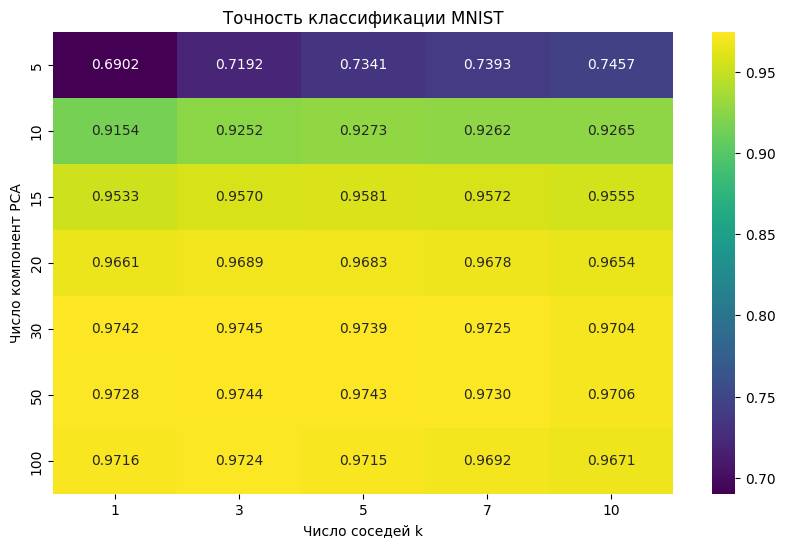

Лучшая комбинация: 30 компонент, k = 3 -> 0.9745
Худшая комбинация: 5 компонент, k = 1 -> 0.6902
Лучший kNN на всех 784 признаках (из 2.4): 0.9690
Комбинаций лучше, чем kNN на полных данных с k=5 (0.9668): 18 из 35
Комбинаций лучше лучшего kNN на полных данных (0.9690): 14 из 35


In [17]:
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

pca100 = my_PCA(n_components=max(n_components_grid)).fit(X_train)
Z_train_all, Z_test_all = pca100.transform(X_train), pca100.transform(X_test)

t0 = time.time()
for i, n_comp in enumerate(n_components_grid):
    # Примените PCA (первые n_comp компонент)
    knn = my_kNN().fit(Z_train_all[:, :n_comp], y_train)
    neighbors = knn.kneighbors(Z_test_all[:, :n_comp], n_neighbors=max(k_grid))
    for j, k in enumerate(k_grid):
        # Обучите kNN (голосование по k ближайшим)
        accuracy_matrix[i, j] = accuracy_score(y_test, knn._vote(neighbors[:, :k]))
print(f'Перебор сетки: {time.time() - t0:.1f} с')

# Контроль: ячейка (50 компонент, k=5) должна совпасть с результатом из 3.1
print('Проверка (50, k=5):', accuracy_matrix[n_components_grid.index(50), k_grid.index(5)],
      'vs 3.1:', accuracies_pca[n_components_list.index(50)])

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.4f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

bi, bj = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
wi, wj = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
print(f'Лучшая комбинация: {n_components_grid[bi]} компонент, k = {k_grid[bj]} -> {accuracy_matrix[bi, bj]:.4f}')
print(f'Худшая комбинация: {n_components_grid[wi]} компонент, k = {k_grid[wj]} -> {accuracy_matrix[wi, wj]:.4f}')
best_full = max(accuracies)
print(f'Лучший kNN на всех 784 признаках (из 2.4): {best_full:.4f}')
print(f'Комбинаций лучше, чем kNN на полных данных с k=5 ({accuracy_my:.4f}): {(accuracy_matrix > accuracy_my).sum()} из {accuracy_matrix.size}')
print(f'Комбинаций лучше лучшего kNN на полных данных ({best_full:.4f}): {(accuracy_matrix > best_full).sum()} из {accuracy_matrix.size}')

**Ответы на вопросы 3.3.**

1. **Наилучшая комбинация: 30 компонент, k = 3 → 0.9745.** Рядом с ней — (50, k = 3) 0.9744, (50, k = 5) 0.9743, (30, k = 1) 0.9742. Область ~30–50 компонент и k = 1–5 даёт практически одинаковый лучший результат.
2. **Наихудшая комбинация: 5 компонент, k = 1 → 0.6902.** При 5 компонентах классы сильно перекрываются, и один ближайший сосед часто оказывается другой цифрой. Обратите внимание: при сильном сжатии большее k *помогает* (0.69 → 0.75 при k = 10), так как голосование усредняет ошибки шумного пространства. При 30–100 компонентах, наоборот, лучше малые k.
3. **Да, 18 из 35 комбинаций лучше kNN на полных данных с k = 5 (0.9668), и 14 из 35 лучше даже лучшего kNN на полных данных (k = 3, 0.9690).** Это все комбинации с 30, 50 компонентами и большинство со 100. PCA не только сокращает размерность в 16–26 раз, но и **улучшает** качество: он удаляет малоинформативные направления, т.е. шум. Однако слишком сильное сжатие (≤ 15 компонент) теряет полезную информацию, и точность падает ниже исходной.

### Дополнительно: проверка лучшей модели на официальной тестовой выборке MNIST

Все эксперименты выше выполнялись на разбиении 60 000 объектов (train + validation). Чтобы убедиться, что выбранные параметры не «подогнаны» под это разбиение, обучим лучшую комбинацию на всех 60 000 объектах и проверим её на официальных 10 000 тестовых изображениях, которые до этого ни разу не использовались.

PCA(30) + kNN(k=3) на официальном тесте MNIST: точность = 0.9741 (ошибка 2.59%), время 20.1 с


kNN(k=5) на сырых 784 признаках, официальный тест:       точность = 0.9688


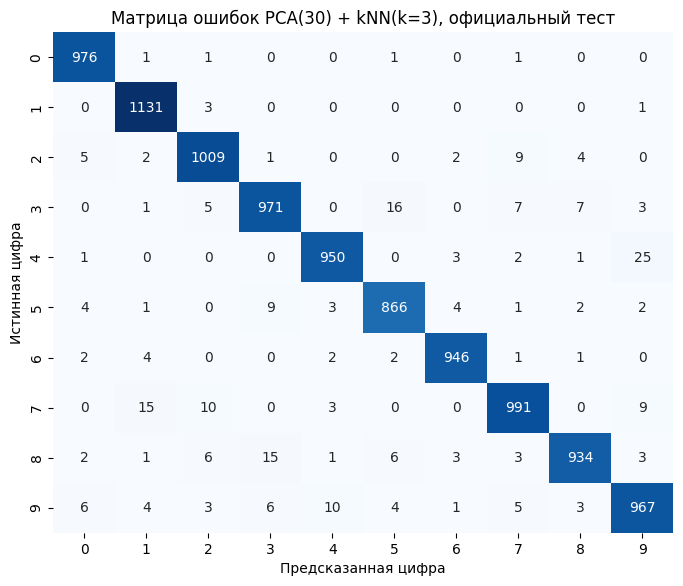

Самые частые ошибки (истинная -> предсказанная): 4->9 (25), 3->5 (16), 7->1 (15), 8->3 (15), 9->4 (10)
Точность по классам: 0:0.996 1:0.996 2:0.978 3:0.961 4:0.967 5:0.971 6:0.987 7:0.964 8:0.959 9:0.958


In [18]:
best_n, best_k = n_components_grid[bi], k_grid[bj]

t0 = time.time()
pca_final = my_PCA(n_components=best_n).fit(X)
knn_final = my_kNN(n_neighbors=best_k).fit(pca_final.transform(X), y)
y_pred_final = knn_final.predict(pca_final.transform(X_mnist_test))
acc_final = accuracy_score(y_mnist_test, y_pred_final)
print(f'PCA({best_n}) + kNN(k={best_k}) на официальном тесте MNIST: точность = {acc_final:.4f} '
      f'(ошибка {1 - acc_final:.2%}), время {time.time() - t0:.1f} с')

knn_raw = my_kNN(n_neighbors=5).fit(X, y)
acc_raw = accuracy_score(y_mnist_test, knn_raw.predict(X_mnist_test))
print(f'kNN(k=5) на сырых 784 признаках, официальный тест:       точность = {acc_raw:.4f}')

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_mnist_test, y_pred_final)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Предсказанная цифра'); plt.ylabel('Истинная цифра')
plt.title(f'Матрица ошибок PCA({best_n}) + kNN(k={best_k}), официальный тест')
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
print('Самые частые ошибки (истинная -> предсказанная):', ', '.join(f'{a}->{b} ({off[a, b]})' for a, b in top))
print('Точность по классам:', ' '.join(f'{d}:{cm[d, d] / cm[d].sum():.3f}' for d in range(10)))

**Результат.** На официальной тестовой выборке MNIST (10 000 изображений, ранее не использовались) PCA(30) + kNN(k = 3), обученный на всех 60 000 изображениях, даёт **точность 0.9741 (ошибка 2.59%)**. Это почти совпадает с результатом на разбиении (0.9745), значит, параметры не переобучены под конкретное разбиение. kNN на сырых 784 признаках даёт 0.9688, т.е. выигрыш PCA подтверждается и на независимых данных.

Чаще всего путаются цифры, похожие по написанию: **4 → 9** (25 ошибок), 3 → 5, 7 → 1, 8 → 3, 9 → 4. Лучше всего распознаются 0 и 1 (99.6%), хуже всего — 8 и 9 (~95.8–95.9%).

## Часть 4. Выводы

1. **PCA** — линейный метод понижения размерности. Данные центрируются, затем находятся собственные векторы ковариационной матрицы (на практике — правые сингулярные векторы центрированной матрицы через SVD), и объекты проецируются на первые k из них. Собственные числа равны дисперсии вдоль компонент, поэтому первые компоненты сохраняют максимум информации. Реализация `my_PCA` через SVD совпадает с `sklearn` (с точным решателем — до ошибок округления float32). На MNIST 154 компоненты из 784 объясняют 95% дисперсии.
2. **kNN** — метрический классификатор без явного обучения: объект получает самый частый класс среди k ближайших по евклидову расстоянию объектов. *Плюсы:* простота, отсутствие обучения, нелинейные границы классов, высокая точность на MNIST (~96.7–96.9%). *Минусы:* медленное предсказание (нужно сравнить с каждым обучающим объектом), большой расход памяти (хранится вся выборка), чувствительность к масштабу признаков, шуму и «проклятию размерности». Векторизованная `my_kNN` дала результат, идентичный `sklearn` (0 расхождений на 18 000 объектах).
3. **PCA улучшает kNN**: при 30–50 компонентах точность выросла с 0.9668 до 0.9745 (ошибок примерно на 22% меньше), а на официальном тесте — с 0.9688 до 0.9741. Поэтому выгоднее уменьшить размерность, а не использовать все признаки: «хвост» компонент с малой дисперсией содержит в основном шум, искажающий расстояния. Но слишком сильное сжатие (≤ 15 компонент) теряет информацию, и точность падает (до 27% при 1 компоненте).
4. **Оптимальная размерность для MNIST — около 30–50 компонент** (с k = 3–5). Эти компоненты объясняют ~73–82% дисперсии: этого достаточно, чтобы сохранить форму цифры, но шум уже отброшен. Интересно, что оптимум для классификации существенно меньше, чем «95% дисперсии» (154 компоненты): для различения классов не нужно восстанавливать изображение точно.
5. **Скорость**: в нашей векторизованной реализации ускорение от PCA оказалось меньше ожидаемого (≈ ×1.3–1.5 для kNN), так как при малых d основное время уходит не на вычисление расстояний ($\propto d$), а на работу с матрицей расстояний 18 000×42 000 (поиск ближайших), которая от d не зависит. Сами расчёты расстояний при этом ускоряются пропорционально размерности. Выигрыш был бы больше при использовании структур данных для поиска соседей (KD-дерево и т.п.), которые эффективны только при малых d.
6. **Самым сложным** было сделать kNN быстрым и не исчерпать память: полная матрица расстояний 18 000×42 000 занимает ~3 ГБ, поэтому пришлось считать её блоками через формулу $\|x\|^2 + \|x'\|^2 - 2\langle x, x'\rangle$ и использовать `argpartition` вместо полной сортировки. Ещё одна тонкость — сравнение с sklearn: при параметрах по умолчанию он использует приближённый randomized SVD, из-за чего последние компоненты отличаются, хотя реализация верна.
7. **Самым интересным** было то, что *выбрасывание* информации (уменьшение признаков в 16–26 раз) улучшает качество классификации, а также картинки главных компонент: PC1 буквально выглядит как «ноль против единицы», что объясняет, почему эти цифры лучше всего разделяются на scatter plot.